In [1]:
# Import libraries

import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
import time
import math
from decimal import Decimal
import inspect
import sys

### 1) Set up an array of ten random numbers between 100 and 500 (just one array with 10 numbers).

In [2]:
#Create an array with ten numbers ranging in value from 100-500
random.seed(123)

factorial = random.sample(range(100, 501), 10)

factorial.sort()

In [3]:
#base code for factorial recursion
#Algorithm calls itself and requires memory to be allocated to at least store the value
#keeps calling function
#stores all hanging function calls
#recursive algorithms are memory intensive

def factorial_rec(x):
    if x <= 1:
        return 1
    else:
        return x * factorial_rec(x-1)
    

In [4]:
#Factorial using loop
#Algorithm only needs to store in memory two variables

def for_loop_fact(x):
    store = 1
    for x in range(1, x + 1):
        store = store * x
    return store


### 2) Calculate the factorial of each of the numbers using a simple FOR loop.  Please capture the start/end times and store the results in an array, or linked list, or dictionary. 

In [5]:
for_loop_time = []

# best of five runs per number, so a one-off delay (e.g. the first call) does not skew the result
for i in range(len(factorial)):
    best = float('inf')
    for run in range(5):
        initiate_count = time.perf_counter()
        for_loop_fact(factorial[i])
        stop_count = time.perf_counter()
        best = min(best, (stop_count - initiate_count) * 1000)
    for_loop_time.append(best)

### 3) Calculate the factorial of each of the numbers using recursion.  Please capture the start/end times and store the results in an array, or linked list, or dictionary.

In [6]:
recursion_time = []

# best of five runs per number, so a one-off delay (e.g. the first call) does not skew the result
for i in range(len(factorial)):
    best = float('inf')
    for run in range(5):
        initiate_count = time.perf_counter()
        factorial_rec(factorial[i])
        stop_count = time.perf_counter()
        best = min(best, (stop_count - initiate_count) * 1000)
    recursion_time.append(best)

### 4) Organize the results of the study into a table showing the number, it's factorial, the time to calculate the factorial using recursion, the time to calculate factorial using FOR loop, and the difference between times.

In [7]:
#put factorials into a list
N = []

for i in range(len(factorial)):
    N.append("{:.5e}".format(Decimal(for_loop_fact(factorial[i]))))

In [8]:
execution_compare = np.array(recursion_time) - np.array(for_loop_time)

In [9]:
table = {"Number": factorial,"Factorial": N, "Loop Time": for_loop_time, "Recursion Time": recursion_time, 
          "Time Difference": execution_compare}



In [10]:
results = pd.DataFrame(table)

In [11]:
results.style.set_caption('Recursive Function & Iterative Function Execution Times')



,Number,Factorial,Loop Time,Recursion Time,Time Difference
0,119,5.57459e+196,0.004655,0.012451,0.007796
1,126,2.37217e+211,0.005203,0.012873,0.007670
2,144,5.55029e+249,0.005698,0.014619,0.008921
3,155,4.78914e+273,0.006276,0.017279,0.011003
4,236,1.25729e+459,0.011805,0.025376,0.013571
5,237,2.97977e+461,0.011630,0.025117,0.013487
6,294,4.41493e+599,0.016137,0.037360,0.021223
7,308,2.26153e+634,0.017544,0.038228,0.020684
8,374,3.26186e+801,0.024526,0.048813,0.024287
9,493,1.62907e+1115,0.039452,0.081266,0.041814


### 5) Use python matplotlib or seaborn to generate a graph that has number on the horizontal axis and with execution time in milliseconds on the vertical axis. The plot should show execution times of recursion and the loop.

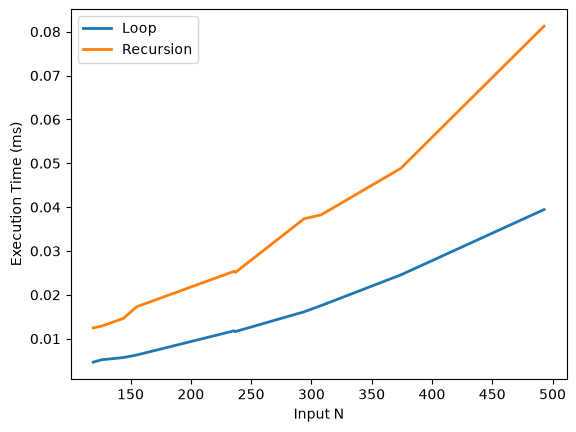

In [12]:
# plot
fig, ax = plt.subplots()
ax.plot(factorial, for_loop_time, linewidth=2.0,label='Loop')
ax.plot(factorial,recursion_time, linewidth=2.0,label='Recursion')
ax.set_xlabel('Input N')
ax.set_ylabel('Execution Time (ms)')
plt.legend()
plt.show()


### EXECUTIVE SUMMARY

INTRODUCTION

This report analyzed the execution time of a recursive algorithm by comparing it to the execution time of an iterative algorithm. One random array was generated composed of the following integers: n = 119, 126, 144, 155, 236, 237, 294, 308, 374, 493. The recursive algorithm and the iterative algorithm were executed to process the integer values in the array from smallest to largest to measure execution times for recursion and iteration. In addition, performance efficiency and the optimal implementation for load increase. 

RECURSIVE ALGORITHM

Recursive algorithms solve problems by calling themselves. A recursive algorithm will have a base case and a recursive case. The base case establishes the parameters which permit the algorithm to stop executing the function.  This form of an algorithm breaks down a problem into smaller components in order to solve the problem. 

INDUSTRY APPLICATION

Recursive algorithms can be implemented on different data structures to accomplish a given objective. A recursive algorithm can be applied to linked lists containing numbers to determine their sum value. If searching for a unique string in a list, then this type of algorithm can be implemented to verify if the unique value is contained in the list. Recursive algorithms can also be used to determine the sorted values of a list and whether it is ascending or descending. The primary concern is performance efficiency and scalability for storage and retrieval. Consideration should be given to the type of system. A recursive algorithm executed in an online analytic processing system would be able to better handle the load for aggregating or summarizing values versus performing the same operation in an online transaction processing system because of execution time. 

METHODOLOGY

A random array of ten integers between 100 and 500 was generated with random.sample using a seed of 123, giving the values 119, 126, 144, 155, 236, 237, 294, 308, 374, 493. For each factorial value in the array, the execution time of the recursive algorithm was appended to a list created to store the values for execution time, using the best of five runs measured with time.perf_counter(). The iterative algorithm was used only for its comparative value and will not be discussed in further detail. 

ANALYSIS & RESULTS

The results displayed on table 1 show the execution time for the recursive algorithm is significantly slower than the execution time for the iterative algorithm. For an integer value of n = 119, the recursive algorithm takes 0.012 milliseconds and the iterative algorithm 0.005 milliseconds. For an integer value of n = 374, the recursive algorithm takes 0.049 milliseconds and the iterative algorithm 0.025 milliseconds. The graphic figure for recursive algorithm displays the increasing execution time as the integer value increases. This represents the increasing number of operations needed to break down the problem until it reaches its base state. At an integer value of n = 493, the iterative algorithm is about twice as fast as the recursive algorithm: 0.081 milliseconds for recursion and 0.039 milliseconds for the loop. The extra time comes from the overhead of a function call and a new stack frame for each step of the recursion.

DISCUSSION OF BIG O NOTATION

Both algorithms perform one multiplication per step from n down to 1, so both take O(n) steps to compute n!. The recursive version also holds n unfinished function calls on the call stack, so it needs O(n) memory, while the loop needs O(1) extra memory beyond the result. The value n! itself grows very quickly, and Python's large integers make each multiplication slower as the number of digits grows, so the measured times rise somewhat faster than linearly. The run time is not O(n!): the factorial is the output, not the number of operations.

CONCLUSION

Both the recursive and the iterative algorithm compute a factorial in O(n) steps, but recursion carries the extra cost of a function call per step and O(n) stack memory, and Python limits recursion depth to about 1,000 calls by default. With storage and retrieval being resources which must be optimized, data systems and their architecture are designed to implement applications with focus on storage and retrieval, given computational processing power is not a limiting factor. The execution times for the iterative algorithm were lower than the execution times of the recursive algorithm.